In [1]:
# Let's import the processed data -
import pandas as pd
data_f=pd.read_csv(r"../data/processed/processed_data.csv")
data_f

,Unnamed: 0,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,15606229,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9996,15569892,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9997,15584532,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


## Current Churn Rate of the Bank -

In [2]:
split_of_customers=data_f["Exited"].value_counts()
split_of_customers

Exited
0    7963
1    2037
Name: count, dtype: int64

## Total Churned Customers - 2037
## Total Retained Customers - 7963

In [3]:
churned=data_f[data_f["Exited"]==1]
(churned["CustomerId"].nunique())*0.01

20.37

## Total Churned Rate - 20.37 %   --> Depicts that 1 out of every 5 customers left the bank which is a concern to be addressed

# CHURN ANALYSIS PER DIFFERENT ATTRIBUTES -

## Customer Engagement Analysis -

2037


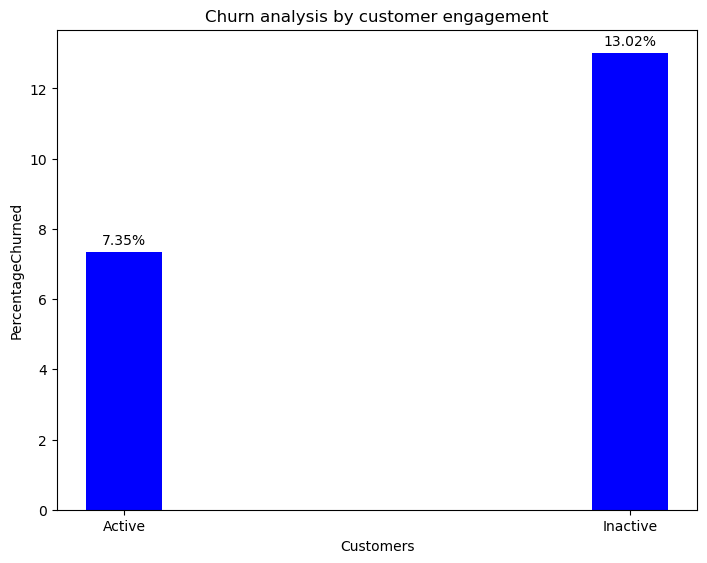

In [4]:
# Lets check that out out the customers who are churned out, how many of them were inactive or active members-
inactive_churned=churned[churned["IsActiveMember"]==0]
inact_ch=(inactive_churned["CustomerId"].nunique())*0.01

# Active churned Customers-
active_churned=churned[churned["IsActiveMember"]==1]
act_ch=(active_churned["CustomerId"].nunique())*0.01

total_customer_engagement=(inactive_churned["CustomerId"].nunique())+(active_churned["CustomerId"].nunique())
print(total_customer_engagement)

# visualize -
import matplotlib.pyplot as plt
fig=plt.figure()
axes=fig.add_axes([0,0,1,1])
ax=axes.bar(["Active","Inactive"],[act_ch,inact_ch],color="b",width=0.15)
plt.xlabel("Customers")
plt.ylabel("PercentageChurned")
plt.title("Churn analysis by customer engagement")
axes.bar_label(ax,fmt="%.2f%%",padding=3)
plt.show()


### Percentage of Inactive churned customers - 13.02 %
### Percentage of Active churned customers - 7.35 %
### It depicts that customers who are not active members of the bank are at higher risk of being churned

## CREDIT CARD CHURN ANALYSIS -

In [5]:
# Credit card holders analysis-
data_f
data_f[data_f["HasCrCard"]==1]

,Unnamed: 0,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
2,2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
4,4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,5,15574012,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
6,6,15592531,822,France,Male,50,7,0.00,2,1,1,10062.80,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9993,9993,15569266,644,France,Male,28,7,155060.41,1,1,0,29179.52,0
9995,9995,15606229,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9996,15569892,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9998,9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [6]:
cr_card=data_f[data_f["HasCrCard"]==1]
cr_card.groupby("Exited")["Exited"].count()

Exited
0    5631
1    1424
Name: Exited, dtype: int64

In [7]:
# percentage churned from the ones having credit card-
count_of_churned=cr_card[cr_card["Exited"]==1]["CustomerId"].nunique()
total_customers=cr_card["CustomerId"].nunique()
proportion_cr_card = (count_of_churned/total_customers)*100
proportion_cr_card

20.184266477675408

In [8]:
cr_card_not=data_f[data_f["HasCrCard"]==0]
cr_card_not.groupby("Exited")["Exited"].count()


Exited
0    2332
1     613
Name: Exited, dtype: int64

In [9]:
# for the non credit card holders -
counts=cr_card_not[cr_card_not["Exited"]==1]["CustomerId"].nunique()
total_customers1=cr_card_not["CustomerId"].nunique()
proportion_no_cr_card = (counts/total_customers1)*100
proportion_no_cr_card

20.814940577249573

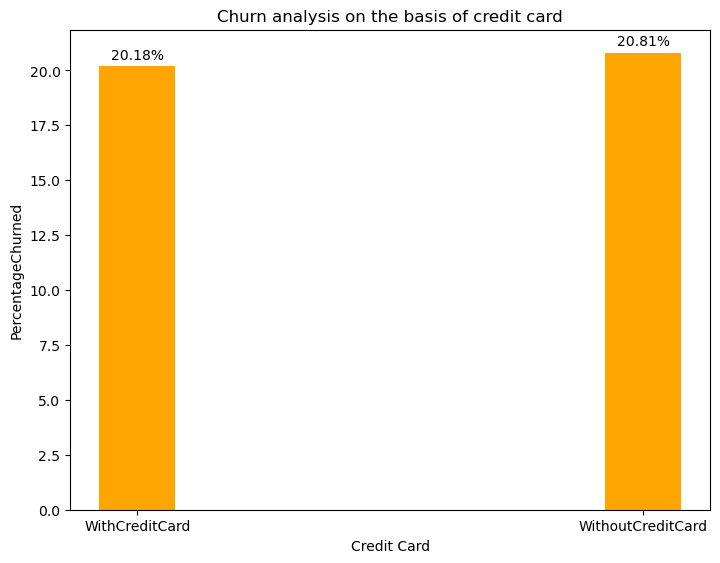

In [10]:
# Churn analysis for credit and non credit card holders -
import matplotlib.pyplot as plt
fig=plt.figure()
axes=fig.add_axes([0,0,1,1])
ax=axes.bar(["WithCreditCard","WithoutCreditCard"],[proportion_cr_card,proportion_no_cr_card],color="orange",width=0.15)
plt.xlabel("Credit Card")
plt.ylabel("PercentageChurned")
plt.title("Churn analysis on the basis of credit card")
axes.bar_label(ax,fmt="%.2f%%",padding=3)
plt.show()

## CHURN ANALYSIS BY NUMBER OF ASSOCIATED PRODUCTS -

In [11]:
# For analysing the effect of Number of products in churning of customers-
data_f

,Unnamed: 0,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,15606229,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9996,15569892,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9997,15584532,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [12]:
# for the customers associated with only one product -
data_one=data_f[data_f["NumOfProducts"]==1]
total_one=data_one["CustomerId"].nunique()
print(total_one)
# for the churned customers-
churned_one=data_one[data_one["Exited"]==1]
total_one_churned=churned_one["CustomerId"].nunique()
print(total_one_churned)

# percentage churned -
per_churn_one=(total_one_churned/total_one)*100
print(per_churn_one)

5084
1409
27.714398111723053


In [13]:
# for the customers assocaited with 2 products -
data_two=data_f[data_f["NumOfProducts"]==2]
total_two=data_two["CustomerId"].nunique()
print(total_two)

# for the churned ones -
churned_two=data_two[data_two["Exited"]==1]
total_two_churned=churned_two["CustomerId"].nunique()
print(total_two_churned)

# percentage churned -
per_churn_two=(total_two_churned/total_two)*100
print(per_churn_two)

4590
348
7.5816993464052285


In [14]:
# for the customers assocaited with 3 products -
data_three=data_f[data_f["NumOfProducts"]==3]
total_three=data_three["CustomerId"].nunique()
print(total_three)

# for the churned ones -
churned_three=data_three[data_three["Exited"]==1]
total_three_churned=churned_three["CustomerId"].nunique()
print(total_three_churned)

# percentage churned -
per_churn_three=(total_three_churned/total_three)*100
print(per_churn_three)

266
220
82.70676691729322


In [15]:
# for the customers assocaited with 4 products -
data_four=data_f[data_f["NumOfProducts"]==4]
total_four=data_four["CustomerId"].nunique()
print(total_four)

# for the churned ones -
churned_four=data_four[data_four["Exited"]==1]
total_four_churned=churned_four["CustomerId"].nunique()
print(total_four_churned)

# percentage churned -
per_churn_four=(total_four_churned/total_four)*100
print(per_churn_four)

60
60
100.0


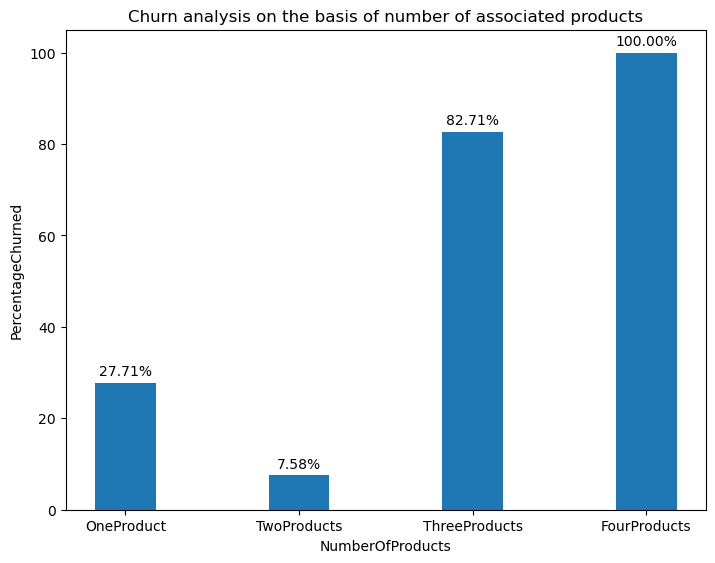

In [16]:
# lets analyse the churning of customers via visual representation -
import matplotlib.pyplot as plt
fig=plt.figure()
axes=fig.add_axes([0,0,1,1])
bar=axes.bar(["OneProduct","TwoProducts","ThreeProducts","FourProducts"],[per_churn_one,per_churn_two,per_churn_three,per_churn_four],width=0.35)
plt.xlabel("NumberOfProducts")
plt.ylabel("PercentageChurned")
plt.title("Churn analysis on the basis of number of associated products")
axes.bar_label(bar, fmt='%.2f%%', padding=3)
plt.show()

## CHURN ANALYSIS BY GEOGRAPHY -

In [17]:
# total customers per geography -
per_geography=data_f.groupby("Geography")["CustomerId"].count()
per_geography

Geography
France     5014
Germany    2509
Spain      2477
Name: CustomerId, dtype: int64

In [18]:
# lets analyse country wise -
country_wise=data_f[data_f["Exited"]==1]
country_wise_churned=country_wise.groupby("Geography")["CustomerId"].count()
country_wise_churned

Geography
France     810
Germany    814
Spain      413
Name: CustomerId, dtype: int64

In [19]:
# percenatge churned in france -
per_churned_france=(country_wise_churned.iloc[0]/per_geography.iloc[0])*100
print(per_churned_france)

# percentage churned in germany -
per_churned_germany=(country_wise_churned.iloc[1]/per_geography.iloc[1])*100
print(per_churned_germany)

# percentage churned in spain -
per_churned_spain=(country_wise_churned.iloc[2]/per_geography.iloc[2])*100
print(per_churned_spain)


16.15476665337056
32.44320446392985
16.673395236172787


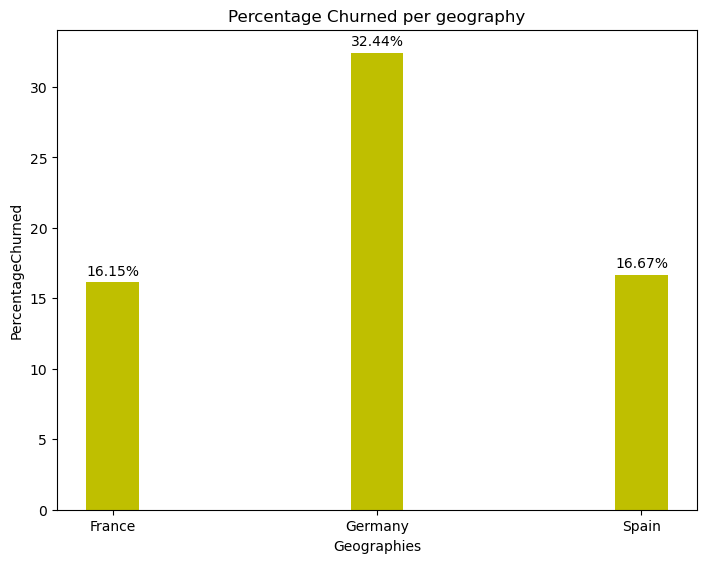

In [20]:
import matplotlib.pyplot as plt
fig=plt.figure()
axes=fig.add_axes([0,0,1,1])
ax=axes.bar(["France","Germany","Spain"],[per_churned_france,per_churned_germany,per_churned_spain], width=0.2,color="y")
plt.xlabel("Geographies")
plt.ylabel("PercentageChurned")
plt.title("Percentage Churned per geography")
axes.bar_label(ax,fmt="%.2f%%",padding=3)
plt.show()

## CHURN ANALYSIS BY AGE GROUP -

In [21]:
# for the reference columns -
data_f["Age_Group"]=pd.cut(data_f["Age"],bins=[17,25,35,45,55,90],labels=["Young Adults","Early/Mid Career","Established Adults","Mature Adults","Senior Customers"])
# data_f


In [22]:
# Young adults chunrn analysis-
age_analysis=data_f[data_f["Exited"]==1]
# age_analysis

In [23]:
# churning rate of Established adults -
ea_total=data_f[data_f["Age_Group"]=="Established Adults"]
total_ea=ea_total["CustomerId"].nunique()
total_ea

# churned-
ch_ea=ea_total[ea_total["Exited"]==1]
total_ch_ea=ch_ea["CustomerId"].nunique()
total_ch_ea

# percentage churned -
per_ch=(total_ch_ea/total_ea)*100
per_ch

19.619914346895076

In [24]:
# churning rate of Early/Mid Career -
emc_total=data_f[data_f["Age_Group"]=="Early/Mid Career"]
total_emc=emc_total["CustomerId"].nunique()
total_emc

# churned-
ch_emc=emc_total[emc_total["Exited"]==1]
total_ch_emc=ch_emc["CustomerId"].nunique()
total_ch_emc

# percentage churned -
per_ch_emc=(total_ch_emc/total_emc)*100
per_ch_emc

8.49802371541502

In [25]:
# churning rate of Senior customers -
sm_total=data_f[data_f["Age_Group"]=="Senior Customers"]
total_sm=sm_total["CustomerId"].nunique()
total_sm

# churned-
ch_sm=sm_total[sm_total["Exited"]==1]
total_ch_sm=ch_sm["CustomerId"].nunique()
total_ch_sm

# percentage churned -
per_ch_sm=(total_ch_sm/total_sm)*100
per_ch_sm

36.84210526315789

In [26]:
# churning rate of Mature Adults -
ma_total=data_f[data_f["Age_Group"]=="Mature Adults"]
total_ma=ma_total["CustomerId"].nunique()
total_ma

# churned-
ch_ma=ma_total[ma_total["Exited"]==1]
total_ch_ma=ch_ma["CustomerId"].nunique()
total_ch_ma

# percentage churned -
per_ch_ma=(total_ch_ma/total_ma)*100
per_ch_ma

50.57208237986271

In [27]:
# churning rate of Young adults -
ya_total=data_f[data_f["Age_Group"]=="Young Adults"]
total_ya=ya_total["CustomerId"].nunique()
total_ya

# churned-
ch_ya=ya_total[ya_total["Exited"]==1]
total_ch_ya=ch_ya["CustomerId"].nunique()
total_ch_ya

# percentage churned -
per_ch_ya=(total_ch_ya/total_ya)*100
per_ch_ya

7.528641571194762

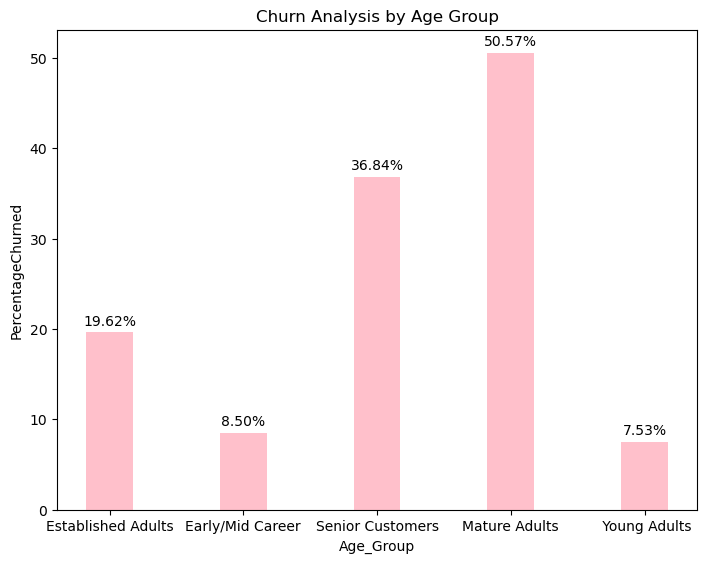

In [28]:
# lets analysse it -
fig=plt.figure()
axes=fig.add_axes([0,0,1,1])
ax=axes.bar(["Established Adults","Early/Mid Career","Senior Customers","Mature Adults"," Young Adults"],[per_ch,per_ch_emc,per_ch_sm,per_ch_ma,per_ch_ya],color="pink",width=0.35)
plt.xlabel("Age_Group")
plt.ylabel("PercentageChurned")
plt.title("Churn Analysis by Age Group")
axes.bar_label(ax,fmt="%.2f%%",padding=3)
plt.show()

## Tenure based churn analysis -


In [29]:
# data_f

In [30]:
# total unique values -
data_f["Tenure"].unique()

array([ 2,  1,  8,  7,  4,  6,  3, 10,  5,  9,  0], dtype=int64)

In [31]:
data_f["TenureGroup"]=pd.cut(data_f["Tenure"],bins=[0,2,5,10],labels=["New Customers","Established Customers","Loyal Customers"])
data_f

,Unnamed: 0,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Age_Group,TenureGroup
0,0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1,Established Adults,New Customers
1,1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,Established Adults,New Customers
2,2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,Established Adults,Loyal Customers
3,3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0,Established Adults,New Customers
4,4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,Established Adults,New Customers
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,15606229,771,France,Male,39,5,0.00,2,1,0,96270.64,0,Established Adults,Established Customers
9996,9996,15569892,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,Early/Mid Career,Loyal Customers
9997,9997,15584532,709,France,Female,36,7,0.00,1,0,1,42085.58,1,Established Adults,Loyal Customers
9998,9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,Established Adults,Established Customers


In [32]:
# new customers churn rate -
new_cust=data_f[data_f["TenureGroup"]=="New Customers"]
tot_new_cust=new_cust["CustomerId"].nunique()

# churned -
churned_new=new_cust[new_cust["Exited"]==1]
tot_churned_new=churned_new["CustomerId"].nunique()
tot_churned_new

# percentage churned -
per_churned_new=(tot_churned_new/tot_new_cust)*100
per_churned_new

20.787325972155546

In [33]:
# new customers churn rate -
estab_cust=data_f[data_f["TenureGroup"]=="Established Customers"]
tot_estab_cust=estab_cust["CustomerId"].nunique()

# churned -
churned_estab=estab_cust[estab_cust["Exited"]==1]
tot_churned_estab=churned_estab["CustomerId"].nunique()
tot_churned_estab

# percentage churned -
per_churned_estab=(tot_churned_estab/tot_estab_cust)*100
per_churned_estab

20.764119601328904

In [34]:
# new customers churn rate -
loyal_cust=data_f[data_f["TenureGroup"]=="Loyal Customers"]
tot_loyal_cust=loyal_cust["CustomerId"].nunique()

# churned -
churned_loyal=loyal_cust[loyal_cust["Exited"]==1]
tot_churned_loyal=churned_loyal["CustomerId"].nunique()
tot_churned_loyal

# percentage churned -
per_churned_loyal=(tot_churned_loyal/tot_loyal_cust)*100
per_churned_loyal

19.670672007120604

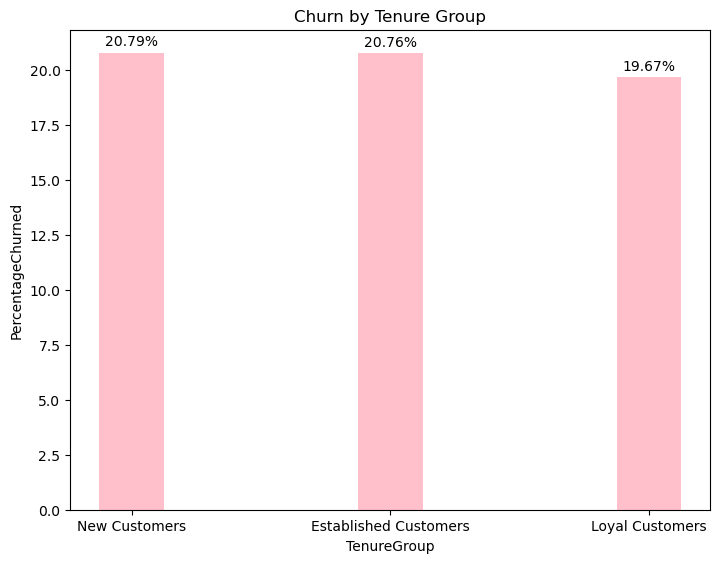

In [35]:
# Visulaize -
fig=plt.figure()
axes=fig.add_axes([0,0,1,1])
ax=axes.bar(["New Customers","Established Customers","Loyal Customers"],[per_churned_new,per_churned_estab,per_churned_loyal],color="pink",width=0.25)
plt.xlabel("TenureGroup")
plt.ylabel("PercentageChurned")
plt.title("Churn by Tenure Group")
axes.bar_label(ax,fmt="%.2f%%",padding=3)
plt.show()

# CROSS PARAMETERS ANALYZATION -

In [36]:
# Lets consider the churning rates of the customers who are active/inactive and number of associated products -
activity_product_churn = pd.crosstab(
    [data_f["IsActiveMember"], data_f["NumOfProducts"]],
    data_f["Exited"],
    normalize="index"
) * 100       # we multiplied by 100 for percentage.

activity_product_churn




Exited                                0           1
IsActiveMember NumOfProducts                       
0              1              63.347878   36.652122
               2              90.111940    9.888060
               3              11.764706   88.235294
               4               0.000000  100.000000
1              1              81.076863   18.923137
               2              94.439902    5.560098
               3              24.778761   75.221239
               4               0.000000  100.000000

### BUSINESS INSIGHTS

#### 1. Customers with two banking products exhibit the lowest churn irrespective of whether they are active or inactive members.

#### 2. Customers with only one product are significantly more likely to leave,indicating lower engagement with the bank.

#### 3. Churn increases sharply for customers owning three products,suggesting that highly cross-sold customers may require further
####    investigation to understand dissatisfaction.

#### 4. Customers with four products show 100% churn in this dataset. However, this category should be interpreted cautiously because the
####    number of observations may be very small, by data_f["NumOfProducts"].value_counts() the count comes as 60.

### Business Insights :-

#### As per the dataset, in all geographies churn rate is comparitively less when a customer is active member and realtively higher when a customer is inactive member.

In [37]:
activity_product_churn

Exited                                0           1
IsActiveMember NumOfProducts                       
0              1              63.347878   36.652122
               2              90.111940    9.888060
               3              11.764706   88.235294
               4               0.000000  100.000000
1              1              81.076863   18.923137
               2              94.439902    5.560098
               3              24.778761   75.221239
               4               0.000000  100.000000

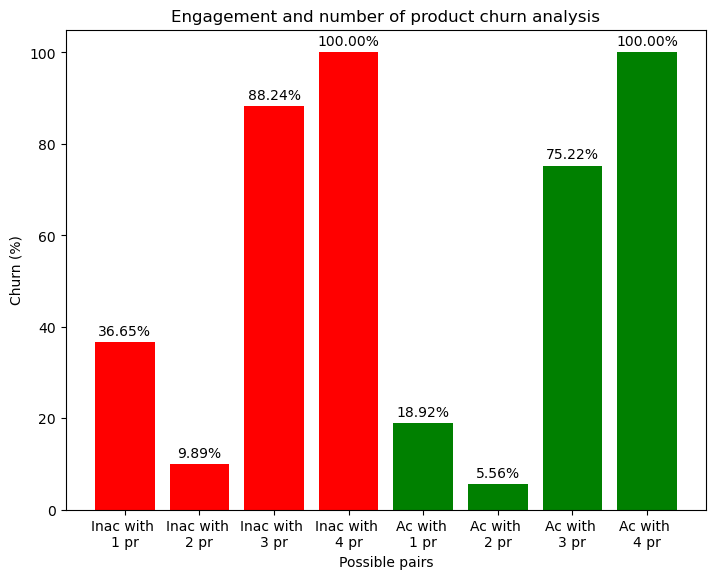

In [38]:
# for the matplotlin analysis-
import matplotlib.pyplot as plt
churned1=activity_product_churn[1]
churned_list=[]
for t in churned1:
    churned_list.append(t)
    

labels2=[]
for t, u in activity_product_churn.index:
    if t==0:
        labels2.append("Inac with \n"+str(u)+" pr")
    else:
        labels2.append("Ac with \n"+str(u)+" pr")
labels2

color1=[]
for v,u in activity_product_churn.index:
    if v==0:
        color1.append("red")
    else:
        color1.append("green")
color1

fig=plt.figure()
axes=fig.add_axes([0,0,1,1])
ax=axes.bar(labels2,churned_list,color=color1)
axes.bar_label(ax,fmt="%.2f%%",padding=3)
plt.xlabel("Possible pairs")
plt.ylabel("Churn (%)")
plt.title("Engagement and number of product churn analysis")
plt.show()

## 2. Next Cross parameters analysis -

In [39]:
data_f

,Unnamed: 0,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Age_Group,TenureGroup
0,0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1,Established Adults,New Customers
1,1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,Established Adults,New Customers
2,2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,Established Adults,Loyal Customers
3,3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0,Established Adults,New Customers
4,4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,Established Adults,New Customers
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,15606229,771,France,Male,39,5,0.00,2,1,0,96270.64,0,Established Adults,Established Customers
9996,9996,15569892,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,Early/Mid Career,Loyal Customers
9997,9997,15584532,709,France,Female,36,7,0.00,1,0,1,42085.58,1,Established Adults,Loyal Customers
9998,9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,Established Adults,Established Customers


In [40]:
# Age group versus credit card analysis -
crcard_age=pd.crosstab([data_f["HasCrCard"],data_f["Age_Group"]],data_f["Exited"],normalize="index")
crcard_age_per_churned=crcard_age[1]*100
crcard_age_per_churned

HasCrCard  Age_Group         
0          Young Adults           9.189189
           Early/Mid Career       7.907908
           Established Adults    18.866253
           Mature Adults         53.750000
           Senior Customers      38.528139
1          Young Adults           6.807512
           Early/Mid Career       8.729847
           Established Adults    19.946298
           Mature Adults         49.176729
           Senior Customers      36.155203
Name: 1, dtype: float64

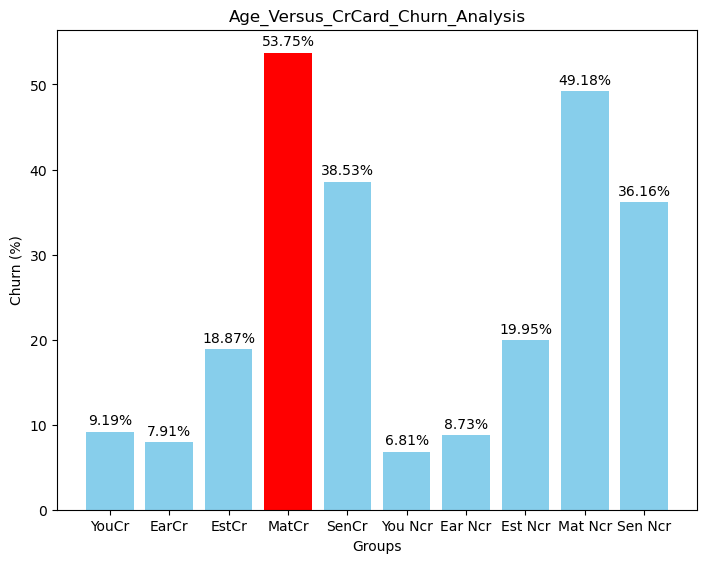

In [41]:
# lets try to understand which combination makes the most vulnerable pair which leaves the bank-
labels1=[]
for t, i in crcard_age.index:
    if t==0:
        labels1.append(i[0:3]+"Cr")
    else:
        labels1.append(i[0:3]+" Ncr")

fig=plt.figure()
axes=fig.add_axes([0,0,1,1])
# ax=axes.bar(labels1,crcard_age_per_churned.values,width=0.40,color="skyblue")

color=[]
for t in crcard_age_per_churned.values:
    if t==crcard_age_per_churned.values.max():
        color.append("red")
    elif t!=crcard_age_per_churned.values.max():
        color.append("skyblue")
        
ax=axes.bar(labels1,crcard_age_per_churned,color=color)
axes.bar_label(ax,fmt="%.2f%%",padding=3)
plt.xlabel("Groups")
plt.ylabel("Churn (%)")
plt.title("Age_Versus_CrCard_Churn_Analysis")
plt.show()
       
        

### 3. Next Cross parameter analysis -

In [42]:
data_f

,Unnamed: 0,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Age_Group,TenureGroup
0,0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1,Established Adults,New Customers
1,1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,Established Adults,New Customers
2,2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,Established Adults,Loyal Customers
3,3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0,Established Adults,New Customers
4,4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,Established Adults,New Customers
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,15606229,771,France,Male,39,5,0.00,2,1,0,96270.64,0,Established Adults,Established Customers
9996,9996,15569892,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,Early/Mid Career,Loyal Customers
9997,9997,15584532,709,France,Female,36,7,0.00,1,0,1,42085.58,1,Established Adults,Loyal Customers
9998,9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,Established Adults,Established Customers


In [43]:
# for the age group and geography analysis -
tenure_age=pd.crosstab([data_f["Age_Group"],data_f["Geography"]],data_f["Exited"],normalize="index")
tenu_age=tenure_age[1]*100
tenu_age

Age_Group           Geography
Young Adults        France        5.228758
                    Germany      11.188811
                    Spain         8.641975
Early/Mid Career    France        5.788635
                    Germany      14.800995
                    Spain         8.538012
Established Adults  France       16.043360
                    Germany      31.362196
                    Spain        14.830508
Mature Adults       France       44.388610
                    Germany      66.997519
                    Spain        41.157556
Senior Customers    France       32.545932
                    Germany      52.830189
                    Spain        28.292683
Name: 1, dtype: float64

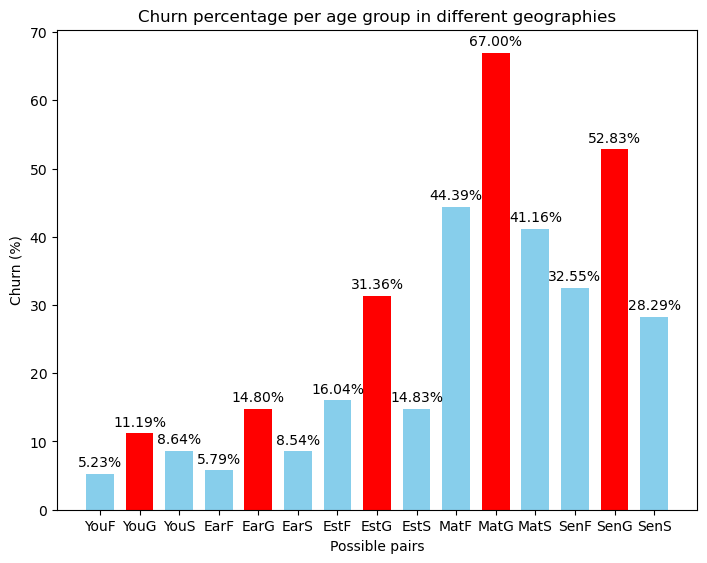

In [44]:
labels3=[]
for t,u in tenu_age.index:
    labels3.append(t[0:3]+u[0:1])
labels3

color=[]
# for a,b in tenu_age.index:
young_adults=(tenure_age.iloc[0:3,1:2])*100
EarlyMidCareer=(tenure_age.iloc[3:6,1:2])*100
EstablishedAdults=(tenure_age.iloc[6:9,1:2])*100
MatureAdults =(tenure_age.iloc[9:12,1:2])*100
SeniorCustomers =(tenure_age.iloc[12:15,1:2])*100


color=[]
for t in young_adults.values:
    if t==young_adults.values.max():
        color.append("red")
    else:
        color.append("skyblue")
for u in EarlyMidCareer.values:
    if u==EarlyMidCareer.values.max():
        color.append("red")
    else:
        color.append("skyblue")
for v in EstablishedAdults.values:
    if v==EstablishedAdults.values.max():
        color.append("red")
    else:
        color.append("skyblue")
for y in MatureAdults.values:
    if y==MatureAdults.values.max():
        color.append("red")
    else:
        color.append("skyblue")
for i in SeniorCustomers.values:
    if i==SeniorCustomers.values.max():
        color.append("red")
    else:
        color.append("skyblue")
    
color

fig=plt.figure()
axes=fig.add_axes([0,0,1,1])
ax=axes.bar(labels3,tenu_age.values,color=color,width=0.70)
plt.xlabel("Possible pairs")
plt.ylabel("Churn (%)")
plt.title("Churn percentage per age group in different geographies")
axes.bar_label(ax,fmt="%.2f%%",padding=3)
plt.show()

## Key Findings -

### 1. Max churn rate - 67.00%
### 2. Most vulnerable pair - Mature adults in Germany
### 3. Least vulnerable pair - Young adults in France
### 4. Max. churn rate of the geography which is least as compared to other country's max. churn rates - Mature adults in France
### 5. Geography that needs urgent attention - Germany as have max. churn rates in majority of age groups

 ### BUSINESS RECOMMENDATION -
#### 1. Germany has most vulnerable pairs irrespective of the age groups, it requires urgent attention and new strategy development initiatives.
#### 2. France needs to focus more on catering mature adults, perhaps via increasing customer benefits and being more reliable towards the customers.
#### 3. Spain also needs to focus on Mature Adults as they are leaving the bank more frequently.
#### 4. Overall, mature adults are most vulnerable followed by seniors and then established adults, there should be more strategy implementation for mature adults so that we can hold them for long, we should take feedback from respective people from this age group and have to work in that direction as we can see the mature adults age group is most vulnerable that clearly depicts that there is some lag from our side in serving those age group. If, there would be a significant drop in churning of mature adults then the overall churn rate will decrease by a good figure.

In [45]:
data_f

,Unnamed: 0,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Age_Group,TenureGroup
0,0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1,Established Adults,New Customers
1,1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,Established Adults,New Customers
2,2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,Established Adults,Loyal Customers
3,3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0,Established Adults,New Customers
4,4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,Established Adults,New Customers
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,15606229,771,France,Male,39,5,0.00,2,1,0,96270.64,0,Established Adults,Established Customers
9996,9996,15569892,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,Early/Mid Career,Loyal Customers
9997,9997,15584532,709,France,Female,36,7,0.00,1,0,1,42085.58,1,Established Adults,Loyal Customers
9998,9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,Established Adults,Established Customers


In [46]:
# to analyze the statistical relation of age on the churn-
a=pd.crosstab(data_f["Gender"],data_f["Exited"])
a

Exited,0,1
Gender,,
Female,3404,1139
Male,4559,898


In [47]:
from scipy.stats import chi2_contingency
chi2,p_gender,dof,expected = chi2_contingency(a)
chi2
p_gender
dof
expected

array([[3617.5909,  925.4091],
       [4345.4091, 1111.5909]])

In [48]:
# for analyzing the geography factor -
b=pd.crosstab(data_f["Geography"],data_f["Exited"])
b

Exited,0,1
Geography,,
France,4204,810
Germany,1695,814
Spain,2064,413


In [49]:
from scipy.stats import chi2_contingency
chi2,p_geography,dof,expected=chi2_contingency(b)
expected

array([[3992.6482, 1021.3518],
       [1997.9167,  511.0833],
       [1972.4351,  504.5649]])

In [50]:
# for the age_group analysis -
c=pd.crosstab(data_f["Age_Group"],data_f["Exited"])
chi2,p_age,dof,expected=chi2_contingency(c)
print(c,end="\n\n")

print(expected)


Exited                 0    1
Age_Group                    
Young Adults         565   46
Early/Mid Career    3241  301
Established Adults  3003  733
Mature Adults        648  663
Senior Customers     504  294

[[ 486.51440288  124.48559712]
 [2820.35027005  721.64972995]
 [2974.82456491  761.17543509]
 [1043.89587918  267.10412082]
 [ 635.41488298  162.58511702]]


In [51]:
# for the tenure analysis -
d=pd.crosstab(data_f["TenureGroup"],data_f["Exited"])
print(d,end="\n\n")
chi2,p_tenure,dof,expected=chi2_contingency(d)
print(expected)

Exited                    0    1
TenureGroup                     
New Customers          1650  433
Established Customers  2385  625
Loyal Customers        3610  884

[[1661.05507458  421.94492542]
 [2400.27641598  609.72358402]
 [3583.66850944  910.33149056]]


In [52]:
# for the Credit card factor -
e=pd.crosstab(data_f["HasCrCard"],data_f["Exited"])
print(e,end="\n\n")
chi2,p_credit,dof,expected=chi2_contingency(e)
print(expected)

Exited        0     1
HasCrCard            
0          2332   613
1          5631  1424

[[2345.1035  599.8965]
 [5617.8965 1437.1035]]


In [53]:
# For the number of the product analysis -
f=pd.crosstab(data_f["NumOfProducts"],data_f["Exited"])
print(f,end="\n\n")
chi2,p_numofprod,dof,expected=chi2_contingency(f)
print(expected)

Exited            0     1
NumOfProducts            
1              3675  1409
2              4242   348
3                46   220
4                 0    60

[[4048.3892 1035.6108]
 [3655.017   934.983 ]
 [ 211.8158   54.1842]
 [  47.778    12.222 ]]


In [55]:
# Table showing variables statistically related -
p_values=[p_gender,p_geography,p_age,p_tenure,p_credit,p_numofprod]
dict=[]
for t in p_values:
    if t<0.05:
        dict.append("Yes")
    else:
        dict.append("No")
    
import pandas as pd
df=pd.DataFrame({"Parameter1":["Gender","Geography","Age Group","Tenure Group","Credit card","Number of products"],"Parameter2":["Exited","Exited","Exited","Exited","Exited","Exited"],"Statistically Related":dict})
df

,Parameter1,Parameter2,Statistically Related
0,Gender,Exited,Yes
1,Geography,Exited,Yes
2,Age Group,Exited,Yes
3,Tenure Group,Exited,No
4,Credit card,Exited,No
5,Number of products,Exited,Yes


### KEY FINDINGS VIA CHI SQUARE TEST -
#### 1. Gender, Geography, Age Group and Number of Products showed statistically significant associations with customer churn (p < 0.05).
#### 2. Tenure Group and Credit Card ownership did not show statistically significant associations with churn at the 5% significance level.
#### 3. Statistical significance indicates association with churn, not that these attributes directly cause customers to leave.


### FINAL BUSINESS INSIGHTS -

### 1. Customer engagement -
#### Inactive customers showed substantially higher churn than active customers, indicating that maintaining customer engagement should be a major retention priority.

### 2. Geography - 
#### Germany emerged as the most vulnerable geography across several age groups, indicating a need for country-specific investigation and retention strategies.

### 3. Age -
#### Mature adults showed comparatively high churn rates, making this segment important for targeted retention initiatives.

### 4. Number of Products -
#### Customers associated with unusual/high product counts showed elevated churn. However, extremely high churn percentages for small groups should be interpreted cautiously because of their small population size.

### 5. Statistical validation -
#### Chi-square testing confirmed statistically significant associations between churn and Gender, Geography, Age Group and Number of Products, while Tenure Group and Credit Card ownership did not show statistically significant associations at the 5% level.

### BUSINESS RECOMMENDATIONS -

#### Recommendation 1 — Improve customer engagement

#### Recommendation 2 — Country-specific retention strategy

#### Recommendation 3 — Focus on high-risk age segments

#### Recommendation 4 — Investigate unusual product usage
